<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTOL/MachineLearningT2_BTVN_Bai4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Du lieu Boston: (506, 13)

Kernel: linear
MSE: 28.630042161088003
R2: 0.6095927289269019
5 gia tri du doan: [26.37 32.78 15.8  24.28 18.15]

Kernel: rbf
MSE: 11.887633091912539
R2: 0.8378969067240989
5 gia tri du doan: [26.21 32.1  14.68 22.09 16.12]

SO SANH SVR:
Kernel     MSE     R2
linear 28.6300 0.6096
   rbf 11.8876 0.8379


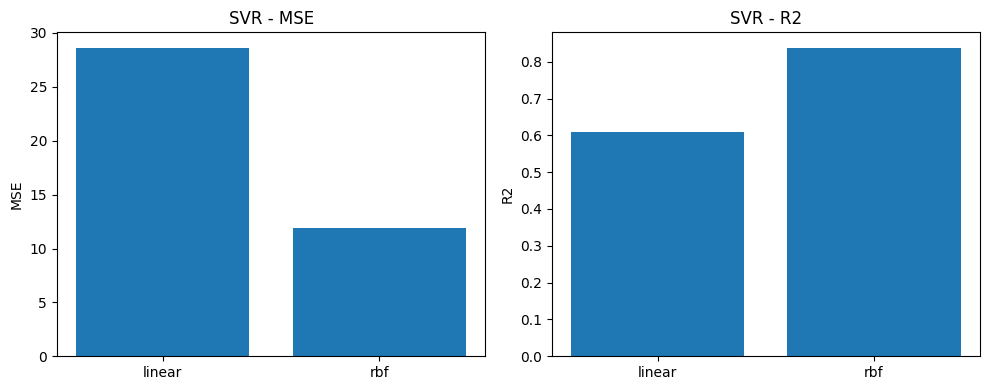

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# 1. Nap Boston Housing
boston = fetch_openml(data_id=531, as_frame=True)

X = boston.data.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(boston.target, errors="coerce")

valid = X.notna().all(axis=1) & y.notna()
X, y = X.loc[valid], y.loc[valid]

print("Du lieu Boston:", X.shape)

# 2. Chia du lieu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Chuan hoa
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 4. Thu kernel linear va rbf
results = []

for kernel in ["linear", "rbf"]:
    model = SVR(
        kernel=kernel,
        C=100,
        epsilon=0.1,
        gamma="scale"
    )

    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)

    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    results.append({
        "Kernel": kernel,
        "MSE": mse,
        "R2": r2
    })

    print("\nKernel:", kernel)
    print("MSE:", mse)
    print("R2:", r2)
    print("5 gia tri du doan:", np.round(pred[:5], 2))

# 5. Bang so sanh
df = pd.DataFrame(results)
print("\nSO SANH SVR:")
print(df.round(4).to_string(index=False))

# 6. Bieu do
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(df["Kernel"], df["MSE"])
axes[0].set_title("SVR - MSE")
axes[0].set_ylabel("MSE")

axes[1].bar(df["Kernel"], df["R2"])
axes[1].set_title("SVR - R2")
axes[1].set_ylabel("R2")

plt.tight_layout()
plt.show()
